<a href="https://colab.research.google.com/github/tlgus9989-art/bigdataHackathon/blob/main/%EA%B8%B0%EB%A7%90_%ED%95%B4%EC%BB%A4%ED%86%A4_%EA%B0%9C%EC%84%A0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN으로 쓰레기 이미지 12종 분류
Kaggle 공개 다운로드 URL에서 archive.zip을 내려받아 사용합니다. Colab에서 T4 GPU를 선택하고 위에서부터 실행하세요. 마지막 사진 예측 셀은 선택 실습입니다.


| 구성 | 실습 위치 |
|---|---|
| CNN 구조·학습·평가 | [8주차 04_fashion_cnn.ipynb](https://github.com/zoomer1975-boop/bigdata/blob/main/week08/04_fashion_cnn.ipynb) |
| Dropout | [9주차 02_dropout.ipynb 셀 12](https://github.com/zoomer1975-boop/bigdata/blob/main/week09/02_dropout.ipynb) |
| Conv 뒤 BatchNorm2d | [9주차 03_batchnorm.ipynb 셀 10·15](https://github.com/zoomer1975-boop/bigdata/blob/main/week09/03_batchnorm.ipynb) |
| 회전·좌우 반전 | [9주차 04_augmentation.ipynb 셀 4·9](https://github.com/zoomer1975-boop/bigdata/blob/main/week09/04_augmentation.ipynb) |
| 설정 비교·정규화 조합 | [9주차 05_experiment.ipynb 셀 6·8·18](https://github.com/zoomer1975-boop/bigdata/blob/main/week09/05_experiment.ipynb) |
추가 비교: 합성곱 3개 모델을 학습률 0.001 및 0.0003에서 평가합니다. 초기화부터 학습하며 모델 선택은 검증 손실 기준입니다. 코드 구문과 크기 계산을 확인했으며 실제 학습은 실행 전입니다.


## 1. URL에서 데이터 다운로드 및 압축 해제
Kaggle의 mostafaabla/garbage-classification 데이터를 Colab에 내려받습니다. 다운로드 후 로컬 이미지 파일을 PyTorch DataLoader로 읽습니다. Colab 런타임이 종료되면 데이터와 결과가 사라질 수 있으므로 학습 후 아래 결과 다운로드 셀을 실행하세요.

In [1]:
from urllib.request import urlretrieve
from pathlib import Path
from tempfile import mkdtemp
from zipfile import ZipFile
import hashlib
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

DATA_URL = "https://www.kaggle.com/api/v1/datasets/download/mostafaabla/garbage-classification"
ZIP_PATH = Path("/content/archive.zip")
print("Kaggle 데이터 다운로드 중...")
urlretrieve(DATA_URL, ZIP_PATH)
print("다운로드 완료")
work = Path(mkdtemp(prefix="trash_", dir="/content"))
with ZipFile(ZIP_PATH) as archive:
    archive.extractall(work)

root = next(p.parent for p in work.rglob("paper") if (p.parent / "plastic").is_dir())
source = datasets.ImageFolder(root)
assert len(source.classes) == 12, source.classes
seed = 12345
torch.manual_seed(seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device, root, len(source), source.classes)

Kaggle 데이터 다운로드 중...
다운로드 완료
cuda /content/trash_04tliaxk/garbage_classification 15515 ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']


## 2. 중복 제거 후 분할
이전 파일과 동일한 시드·분할 방식을 사용합니다. 각 클래스의 약 70%는 학습, 15%는 검증, 15%는 시험입니다. 바이트가 완전히 같은 파일만 중복으로 제거하므로 재압축·유사 사진은 별도 확인이 필요합니다.

In [2]:
from collections import defaultdict

by_hash = defaultdict(list)
for idx, (path, label) in enumerate(source.samples):
    digest = hashlib.sha256(Path(path).read_bytes()).digest()
    by_hash[digest].append((idx, label))

by_class = defaultdict(list)
for group in by_hash.values():
    if len({label for _, label in group}) == 1:
        idx, label = group[0]
        by_class[label].append(idx)

rng = torch.Generator().manual_seed(seed)
train_ids, val_ids, test_ids = [], [], []
print("클래스 | 학습 | 검증 | 시험")
for label, name in enumerate(source.classes):
    ids = by_class[label]
    ids = [ids[i] for i in torch.randperm(len(ids), generator=rng).tolist()]
    n_val = n_test = int(len(ids) * 0.15)
    n_train = len(ids) - n_val - n_test
    train_ids.extend(ids[:n_train])
    val_ids.extend(ids[n_train:n_train + n_val])
    test_ids.extend(ids[n_train + n_val:])
    print(name, n_train, n_val, n_test)
print("중복·라벨 충돌로 제외:", len(source) - len(train_ids) - len(val_ids) - len(test_ids))

클래스 | 학습 | 검증 | 시험
battery 663 141 141
biological 691 147 147
brown-glass 425 91 91
cardboard 625 133 133
clothes 3728 798 798
green-glass 430 92 92
metal 538 115 115
paper 736 157 157
plastic 605 129 129
shoes 1385 296 296
trash 489 104 104
white-glass 542 115 115
중복·라벨 충돌로 제외: 22


## 3. 데이터 전처리와 학습 결과 저장 폴더

In [3]:
from datetime import datetime
import json

run_dir = Path("/content") / ("trash_course_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
run_dir.mkdir()

plain_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])
aug_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])
plain_data = datasets.ImageFolder(root, transform=plain_tf)
aug_data = datasets.ImageFolder(root, transform=aug_tf)

train_eval_loader = DataLoader(Subset(plain_data, train_ids), batch_size=64, shuffle=False)
val_loader = DataLoader(Subset(plain_data, val_ids), batch_size=64, shuffle=False)
test_loader = DataLoader(Subset(plain_data, test_ids), batch_size=64, shuffle=False)

splits = {"train": train_ids, "val": val_ids, "test": test_ids}
manifest = {name: [{"path": str(Path(source.samples[i][0]).relative_to(root)),
                    "label": source.samples[i][1]} for i in ids] for name, ids in splits.items()}
(run_dir / "splits.json").write_text(json.dumps(
    {"classes": source.classes, "seed": seed, "splits": manifest},
    ensure_ascii=False, indent=2), encoding="utf-8")
print("저장 폴더:", run_dir)

저장 폴더: /content/trash_course_20261119_001407_087346


## 4. CNN 모델 작성
합성곱의 padding을 1로 두어 가로와 세로 크기를 유지합니다. 기본 모델은 최대 풀링 두 번으로 16×16 특징 맵을 만듭니다. 추가 모델은 합성곱·BatchNorm·ReLU·풀링을 한 번 더 적용해 128×8×8로 만듭니다.
완전연결층 입력은 16,384개에서 8,192개로 줄어듭니다. 합성곱 3개 구성은 수업에서 배운 층을 반복한 이번 과제의 응용입니다. 실제 성능 개선은 검증 결과로 판단합니다.

In [4]:
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self, n_classes, dropout=0.0, batchnorm=False, deeper=False):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.batchnorm = batchnorm
        if batchnorm:
            self.bn1 = nn.BatchNorm2d(32)
            self.bn2 = nn.BatchNorm2d(64)
        self.deeper = deeper
        if deeper:
            self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
            if batchnorm:
                self.bn3 = nn.BatchNorm2d(128)
            self.fc1 = nn.Linear(128 * 8 * 8, 256)
        else:
            self.fc1 = nn.Linear(64 * 16 * 16, 256)
        self.fc2 = nn.Linear(256, n_classes)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.conv1(x)
        if self.batchnorm:
            x = self.bn1(x)
        x = F.max_pool2d(F.relu(x), 2)     # (32, 32, 32)

        x = self.conv2(x)
        if self.batchnorm:
            x = self.bn2(x)
        x = F.max_pool2d(F.relu(x), 2)     # (64, 16, 16)

        if self.deeper:
            x = self.conv3(x)
            if self.batchnorm:
                x = self.bn3(x)
            x = F.max_pool2d(F.relu(x), 2)  # (128, 8, 8)

        x = x.flatten(1)                   # 배치 차원을 유지하며 펼치기
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        return self.fc2(self.dropout(x))   # 클래스별 점수

### 한 배치의 입력과 출력 확인

In [5]:
model = CNN(len(source.classes)).to(device)
print(model)
bx, by = next(iter(val_loader))
model.eval()
with torch.no_grad():
    out = model(bx.to(device))
print("입력:", bx.shape, "정답:", by.shape, "출력:", out.shape)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=16384, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=12, bias=True)
  (dropout): Dropout(p=0.0, inplace=False)
)
입력: torch.Size([64, 3, 64, 64]) 정답: torch.Size([64]) 출력: torch.Size([64, 12])


## 5. 손실과 정확도 계산
평가할 때는 model.eval()로 Dropout을 끄고, BatchNorm은 학습 중 기록한 평균과 분산을 사용합니다.

In [6]:
loss_fn = nn.CrossEntropyLoss()

def measure(model, loader):
    model.eval()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
    return loss_sum / total, correct / total

## 6. 학습
다섯 실험에서 같은 학습 코드를 사용합니다. 매 epoch이 끝나면 검증 손실을 확인해 가장 낮은 회차의 모델을 저장합니다. 검증 손실이 4회 연속 개선되지 않으면 학습을 마칩니다.

In [7]:
def train_model(name, training_data, dropout, batchnorm, lr, deeper=False):
    torch.manual_seed(seed)
    model = CNN(len(source.classes), dropout, batchnorm, deeper).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_loader = DataLoader(
        Subset(training_data, train_ids), batch_size=64, shuffle=True,
        generator=torch.Generator().manual_seed(seed)
    )
    best_loss = float("inf")
    stale = 0
    history = []
    checkpoint = run_dir / (name + ".pt")
    print("\n실험:", name)

    for epoch in range(1, 26):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        train_loss, train_acc = measure(model, train_eval_loader)
        val_loss, val_acc = measure(model, val_loader)
        history.append({"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
                        "val_loss": val_loss, "val_acc": val_acc})
        print(f"{epoch:02d}회 | 학습 손실 {train_loss:.4f} 정확도 {train_acc:.2%} | "
              f"검증 손실 {val_loss:.4f} 정확도 {val_acc:.2%} | "
              f"정확도 차이 {(train_acc-val_acc)*100:.2f}%p")

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch
            best_acc = val_acc
            stale = 0
            torch.save({"state": model.state_dict(), "config": {"name": name, "dropout": dropout, "batchnorm": batchnorm, "lr": lr, "augment": training_data is aug_data, "deeper": deeper},
                        "classes": source.classes, "epoch": epoch,
                        "val_loss": val_loss, "seed": seed}, checkpoint)
        else:
            stale += 1
        (run_dir / (name + "_history.json")).write_text(
            json.dumps(history, indent=2), encoding="utf-8")
        if stale >= 4:
            print("검증 손실이 4회 연속 개선되지 않아 학습 종료")
            break

    return {"name": name, "checkpoint": str(checkpoint),
                    "val_loss": best_loss, "val_acc": best_acc, "epoch": best_epoch}

### 다섯 가지 설정 비교
기본 CNN을 먼저 학습합니다. 두 번째 실험은 데이터 증강·BatchNorm·Dropout을 함께 적용하고, 세 번째 실험은 두 번째와 같은 조건에서 학습률만 낮춥니다.
합성곱 3개 조합도 두 학습률에서 비교합니다. 추가된 두 실험만큼 실행 시간이 늘어납니다.

In [8]:
basic = train_model("basic", plain_data, dropout=0.0, batchnorm=False, lr=0.001)
combo = train_model("combo", aug_data, dropout=0.3, batchnorm=True, lr=0.001)
combo_low_lr = train_model("combo_low_lr", aug_data, dropout=0.3, batchnorm=True, lr=0.0003)

deep = train_model("deep", aug_data, dropout=0.3, batchnorm=True, lr=0.001, deeper=True)
deep_low_lr = train_model("deep_low_lr", aug_data, dropout=0.3, batchnorm=True, lr=0.0003, deeper=True)

results = [basic, combo, combo_low_lr, deep, deep_low_lr]
print("\n설정별 최적 회차 결과")
for row in results:
    print(row["name"], "| 회차", row["epoch"],
          f'| 검증 손실 {row["val_loss"]:.4f} | 검증 정확도 {row["val_acc"]:.2%}')
chosen = min(results, key=lambda row: row["val_loss"])
print("검증 손실 기준 선택:", chosen["name"])
(run_dir / "comparison.json").write_text(json.dumps(results, indent=2), encoding="utf-8")


실험: basic
01회 | 학습 손실 1.0878 정확도 63.39% | 검증 손실 1.1371 정확도 61.22% | 정확도 차이 2.17%p
02회 | 학습 손실 0.7634 정확도 74.80% | 검증 손실 0.8837 정확도 71.23% | 정확도 차이 3.57%p
03회 | 학습 손실 0.6095 정확도 80.16% | 검증 손실 0.8197 정확도 72.95% | 정확도 차이 7.21%p
04회 | 학습 손실 0.5037 정확도 83.80% | 검증 손실 0.7925 정확도 74.98% | 정확도 차이 8.82%p
05회 | 학습 손실 0.4541 정확도 84.89% | 검증 손실 0.8154 정확도 73.38% | 정확도 차이 11.50%p
06회 | 학습 손실 0.2948 정확도 90.72% | 검증 손실 0.8046 정확도 75.50% | 정확도 차이 15.22%p
07회 | 학습 손실 0.2136 정확도 93.51% | 검증 손실 0.8639 정확도 75.54% | 정확도 차이 17.97%p
08회 | 학습 손실 0.1785 정확도 94.49% | 검증 손실 0.9379 정확도 74.98% | 정확도 차이 19.51%p
검증 손실이 4회 연속 개선되지 않아 학습 종료

실험: combo
01회 | 학습 손실 1.3189 정확도 55.40% | 검증 손실 1.3160 정확도 55.61% | 정확도 차이 -0.21%p
02회 | 학습 손실 1.1287 정확도 62.06% | 검증 손실 1.1502 정확도 61.13% | 정확도 차이 0.93%p
03회 | 학습 손실 1.0679 정확도 63.33% | 검증 손실 1.1205 정확도 61.82% | 정확도 차이 1.51%p
04회 | 학습 손실 0.9787 정확도 65.81% | 검증 손실 1.0452 정확도 63.93% | 정확도 차이 1.88%p
05회 | 학습 손실 0.9222 정확도 68.32% | 검증 손실 0.9808 정확도 66.48% | 정확도 차이 1.84%p
06회 | 학습 손

982

### 선택한 모델의 손실 곡선
학습 손실이 줄어드는 동안 검증 손실이 계속 커지는 구간이 있는지 확인합니다.

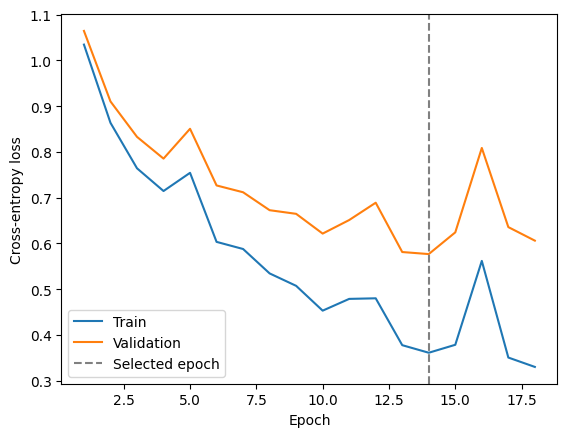

In [9]:
import matplotlib.pyplot as plt

history = json.loads((run_dir / (chosen["name"] + "_history.json")).read_text())
epochs = [row["epoch"] for row in history]
plt.plot(epochs, [row["train_loss"] for row in history], label="Train")
plt.plot(epochs, [row["val_loss"] for row in history], label="Validation")
plt.axvline(chosen["epoch"], linestyle="--", color="gray", label="Selected epoch")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.show()

## 7. 최종 시험 평가
검증 손실로 선택한 모델 하나를 시험 데이터에서 평가합니다. 시험 결과를 보고 설정을 계속 바꾸면 시험셋도 모델 선택에 사용한 셈이므로 독립적인 성능 추정이 어려워집니다.

In [10]:
saved = torch.load(chosen["checkpoint"], map_location=device, weights_only=True)
config = saved["config"]
model = CNN(len(saved["classes"]), config["dropout"], config["batchnorm"], config.get("deeper", False)).to(device)
model.load_state_dict(saved["state"])
test_loss, test_acc = measure(model, test_loader)
train_loss, train_acc = measure(model, train_eval_loader)
val_loss, val_acc = measure(model, val_loader)

print("선택 모델:", config["name"], "| 선택 회차:", saved["epoch"])
print(f"학습 정확도 {train_acc:.2%} | 검증 정확도 {val_acc:.2%} | 시험 정확도 {test_acc:.2%}")
print(f"시험 손실 {test_loss:.4f}")

correct = torch.zeros(len(source.classes))
total = torch.zeros(len(source.classes))
model.eval()
with torch.no_grad():
    for x, y in test_loader:
        pred = model(x.to(device)).argmax(dim=1).cpu()
        for c in range(len(source.classes)):
            mask = y == c
            total[c] += mask.sum()
            correct[c] += (pred[mask] == c).sum()

recall = correct / total.clamp_min(1)
for name, hit, count, rate in zip(source.classes, correct, total, recall):
    print(f"{name:12s} {int(hit):4d}/{int(count):4d} | 재현율 {rate:.2%}")
print(f"클래스 평균 재현율 {recall[total > 0].mean():.2%}")
(run_dir / "test_result.json").write_text(json.dumps(
    {"model": config["name"], "train_acc": train_acc, "val_acc": val_acc,
     "test_acc": test_acc, "test_loss": test_loss,
     "classes": source.classes, "recall": recall.tolist()}, indent=2), encoding="utf-8")

선택 모델: deep_low_lr | 선택 회차: 14
학습 정확도 88.73% | 검증 정확도 81.28% | 시험 정확도 80.07%
시험 손실 0.6021
battery       118/ 141 | 재현율 83.69%
biological    108/ 147 | 재현율 73.47%
brown-glass    62/  91 | 재현율 68.13%
cardboard      99/ 133 | 재현율 74.44%
clothes       759/ 798 | 재현율 95.11%
green-glass    85/  92 | 재현율 92.39%
metal          74/ 115 | 재현율 64.35%
paper         106/ 157 | 재현율 67.52%
plastic        77/ 129 | 재현율 59.69%
shoes         223/ 296 | 재현율 75.34%
trash          78/ 104 | 재현율 75.00%
white-glass    67/ 115 | 재현율 58.26%
클래스 평균 재현율 73.95%


660